# FFT 기반 Adaptive KV Compression

```
K, V -> rFFT(head_dim) -> frequency selector -> mask -> irFFT -> 기존 attention
```
* 기존 모델 weight는 **전부 freeze**

## selector 넣을 위치
* transformers v5의 `Qwen3Attention.forward`는 RoPE를 적용한 뒤 딱 한 줄로
`past_key_values.update(key_states, value_states, layer_idx)`를 부르고 그 반환값으로 attention을
계산함 
* `DynamicCache.update`만 감싸면 "캐시에 들어가는 KV"와 "attention이 보는 KV"를 한꺼번에 바꿀 수 있음

## 0. 설정

In [52]:
%load_ext autoreload
%autoreload 2

import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import torch

import tools
from custom_layers import FFTCompressedCache, KVFreqCompressor, SparseSpectralCache

# ---------------------------------------------------------------- 실험 설정
MODEL = "Qwen/Qwen3-0.6B"   # bf16. FP8 체크포인트는 selector로 역전파가 안 되므로 쓰지 않는다
CORPUS = "gutenberg"        # "tinystories" 또는 로컬 .txt 경로도 된다
SEQ_LEN = 256
BATCH_SIZE = 2
N_BATCHES = 100             # 학습 90 + 검증 10
EPOCHS = 3
LR = 3e-4

QUICK = False               # True면 아래 값으로 줄여서 돌린다 (구조 확인용)
if QUICK:
    SEQ_LEN, BATCH_SIZE, N_BATCHES, EPOCHS = 128, 1, 20, 1

RESULTS = Path("results")
(RESULTS / "selectors").mkdir(parents=True, exist_ok=True)
summary: dict = {}          # 마지막에 json으로 떨어뜨릴 측정값들

tools.set_seed(0)
print(torch.__version__, torch.cuda.get_device_name(0))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
2.14.1+cu130 NVIDIA GeForce RTX 5080


## 1. 모델과 데이터

teacher와 student는 **같은 weight**다. 차이는 캐시가 KV를 그대로 흘려보내는지, spectral filter를
통과시키는지 뿐이다. 그래서 측정되는 모든 차이는 압축 탓이라고 말할 수 있다.

In [53]:
model, tok = tools.load_model(MODEL)
info = tools.describe_model(model)
info

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

{'layers': 28,
 'hidden': 1024,
 'q_heads': 16,
 'kv_heads': 8,
 'head_dim': 128,
 'n_freq': 65,
 'vocab': 151936,
 'dtype': 'torch.bfloat16'}

In [54]:
# freeze 확인. 학습 가능한 파라미터가 하나라도 남아 있으면 실험이 성립하지 않는다.
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable in base model: {n_train}  (0이어야 한다)")
print(f"head_dim={info['head_dim']}  ->  rFFT 계수 {info['n_freq']}개 (bin 0 .. {info['head_dim']//2})")

trainable in base model: 0  (0이어야 한다)
head_dim=128  ->  rFFT 계수 65개 (bin 0 .. 64)


In [55]:
text = tools.load_text(CORPUS)
batches = tools.make_batches(tok, text, seq_len=SEQ_LEN, batch_size=BATCH_SIZE,
                             n_batches=N_BATCHES, device=model.device)
n_val = max(2, N_BATCHES // 10)
train_batches, val_batches = batches[:-n_val], batches[-n_val:]
print(f"{len(text):,} chars -> {len(batches)} batches of {tuple(batches[0].shape)}"
      f"  (train {len(train_batches)} / val {len(val_batches)})")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (174851 > 131072). Running this sequence through the model will result in indexing errors


748,167 chars -> 100 batches of (2, 256)  (train 90 / val 10)


## 2. 가설점검

핵심 가설은 "K/V latent를 FFT basis로 보면 downstream 예측에 필요한 정보가 **적은 수의 주파수에
모여 있다**"는 것

1. **에너지 분포** — 크기 순 상위 m개 계수에 전체 에너지의 몇 %가 모이는지
2. **truncation 민감도** — 학습 없이 계수를 잘라냈을 때 출력이 얼마나 깨지는지
3. **레이어별 민감도** — 한 레이어씩만 잘라서 민감도분석

2번과 3번의 기준선 세 개를 계속 쓴다.

* energy: 계수 크기 상위 k개. 학습 없이 체크가능 
* lowpass: 낮은 주파수 k개. 학습 없는 **정적** 기준선
* random: 무작위 k개. 대조군

cache: (1, 8, 256, 128) (batch, heads, seq, head_dim)

[Layer  0 Keys  ] len=262144  rfft bins=131073  DC=24508.16  IFFT max err=3.05e-05
    bin    9984  freq 0.038086  (period      26.3 samples)  |X|=332972.66
    bin  119040  freq 0.454102  (period       2.2 samples)  |X|=331716.72
    bin   98560  freq 0.375977  (period       2.7 samples)  |X|=328810.38
    bin   14080  freq 0.053711  (period      18.6 samples)  |X|=326871.69
    bin  110848  freq 0.422852  (period       2.4 samples)  |X|=325833.91
[Layer  0 Values] len=262144  rfft bins=131073  DC=682.81  IFFT max err=2.38e-07
    bin   57856  freq 0.220703  (period       4.5 samples)  |X|=920.08
    bin  129536  freq 0.494141  (period       2.0 samples)  |X|=912.52
    bin  103936  freq 0.396484  (period       2.5 samples)  |X|=901.18
    bin   96512  freq 0.368164  (period       2.7 samples)  |X|=726.48
    bin   96000  freq 0.366211  (period       2.7 samples)  |X|=702.38


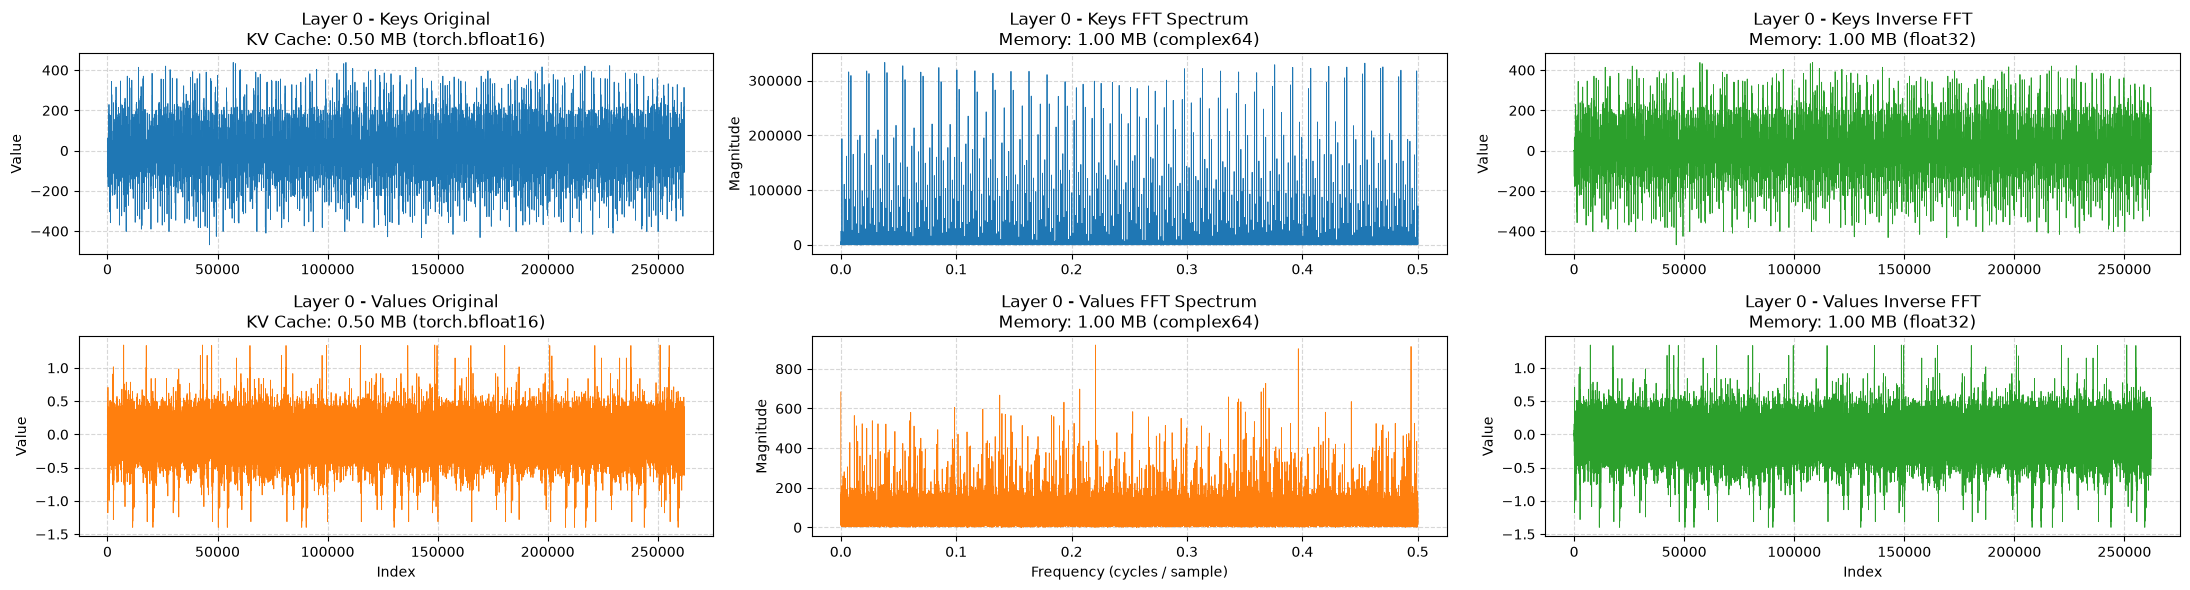

[Layer  7 Keys  ] len=262144  rfft bins=131073  DC=9621.21  IFFT max err=1.14e-05
    bin   52992  freq 0.202148  (period       4.9 samples)  |X|=91692.84
    bin  116992  freq 0.446289  (period       2.2 samples)  |X|=81878.30
    bin   47360  freq 0.180664  (period       5.5 samples)  |X|=81756.24
    bin  112384  freq 0.428711  (period       2.3 samples)  |X|=81116.29
    bin  116480  freq 0.444336  (period       2.3 samples)  |X|=80568.27
[Layer  7 Values] len=262144  rfft bins=131073  DC=1243.66  IFFT max err=4.77e-07
    bin   50176  freq 0.191406  (period       5.2 samples)  |X|=3319.22
    bin   64256  freq 0.245117  (period       4.1 samples)  |X|=3209.78
    bin   95488  freq 0.364258  (period       2.7 samples)  |X|=3170.68
    bin  124672  freq 0.475586  (period       2.1 samples)  |X|=3093.48
    bin   22528  freq 0.085938  (period      11.6 samples)  |X|=3083.66


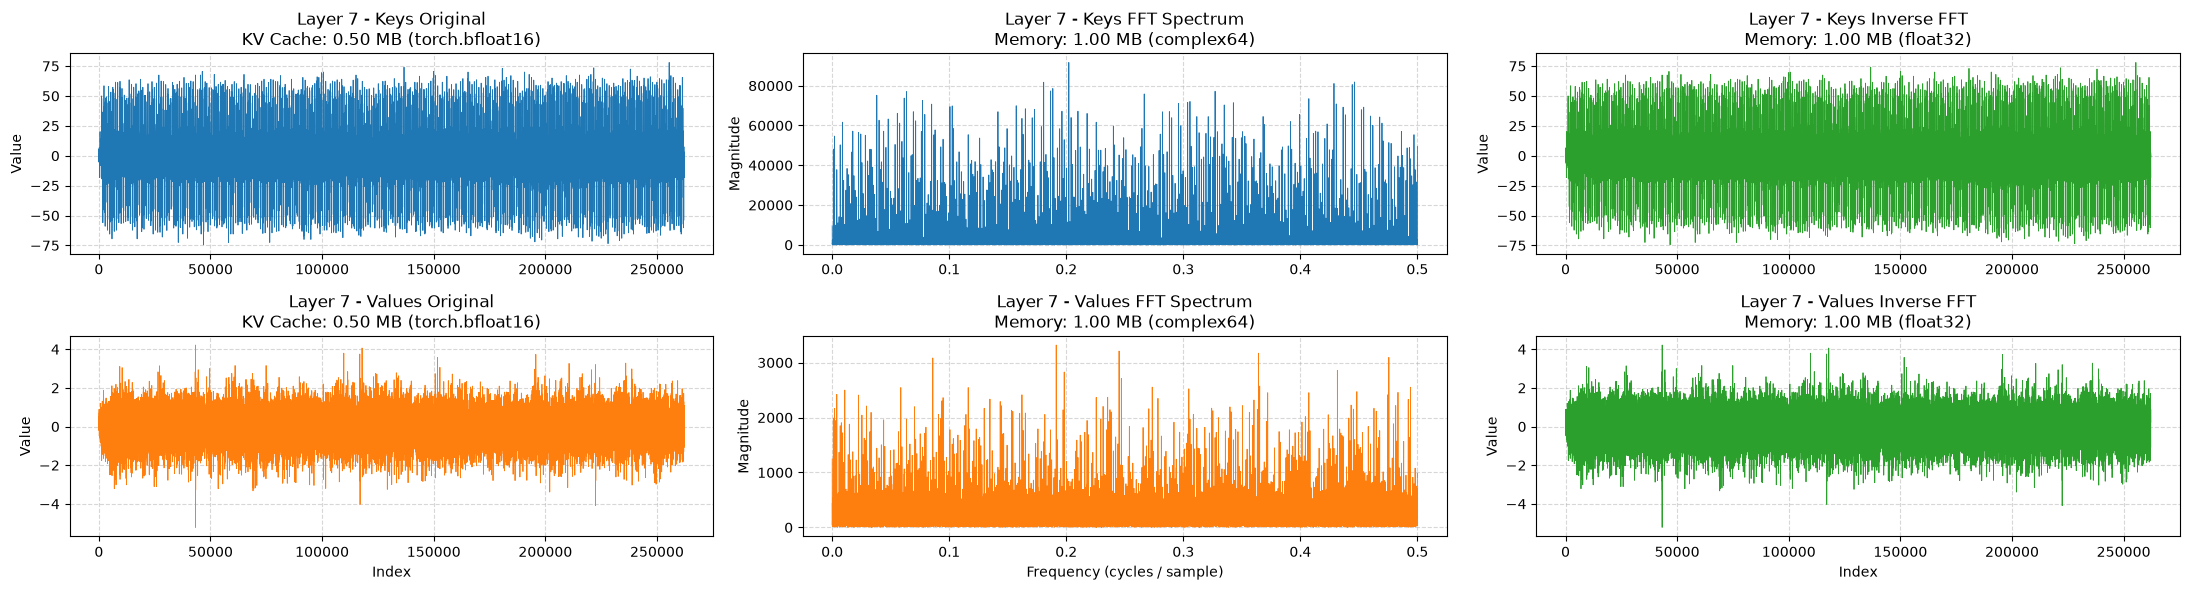

[Layer 14 Keys  ] len=262144  rfft bins=131073  DC=32002.90  IFFT max err=3.34e-06
    bin   57344  freq 0.218750  (period       4.6 samples)  |X|=38417.55
    bin   90112  freq 0.343750  (period       2.9 samples)  |X|=37471.98
    bin   40960  freq 0.156250  (period       6.4 samples)  |X|=35052.72
    bin   61440  freq 0.234375  (period       4.3 samples)  |X|=34366.82
    bin  120832  freq 0.460938  (period       2.2 samples)  |X|=34194.55
[Layer 14 Values] len=262144  rfft bins=131073  DC=1170.44  IFFT max err=3.81e-06
    bin   59904  freq 0.228516  (period       4.4 samples)  |X|=7334.29
    bin   87040  freq 0.332031  (period       3.0 samples)  |X|=6723.60
    bin  125440  freq 0.478516  (period       2.1 samples)  |X|=6721.18
    bin   87552  freq 0.333984  (period       3.0 samples)  |X|=6696.81
    bin   68864  freq 0.262695  (period       3.8 samples)  |X|=6670.92


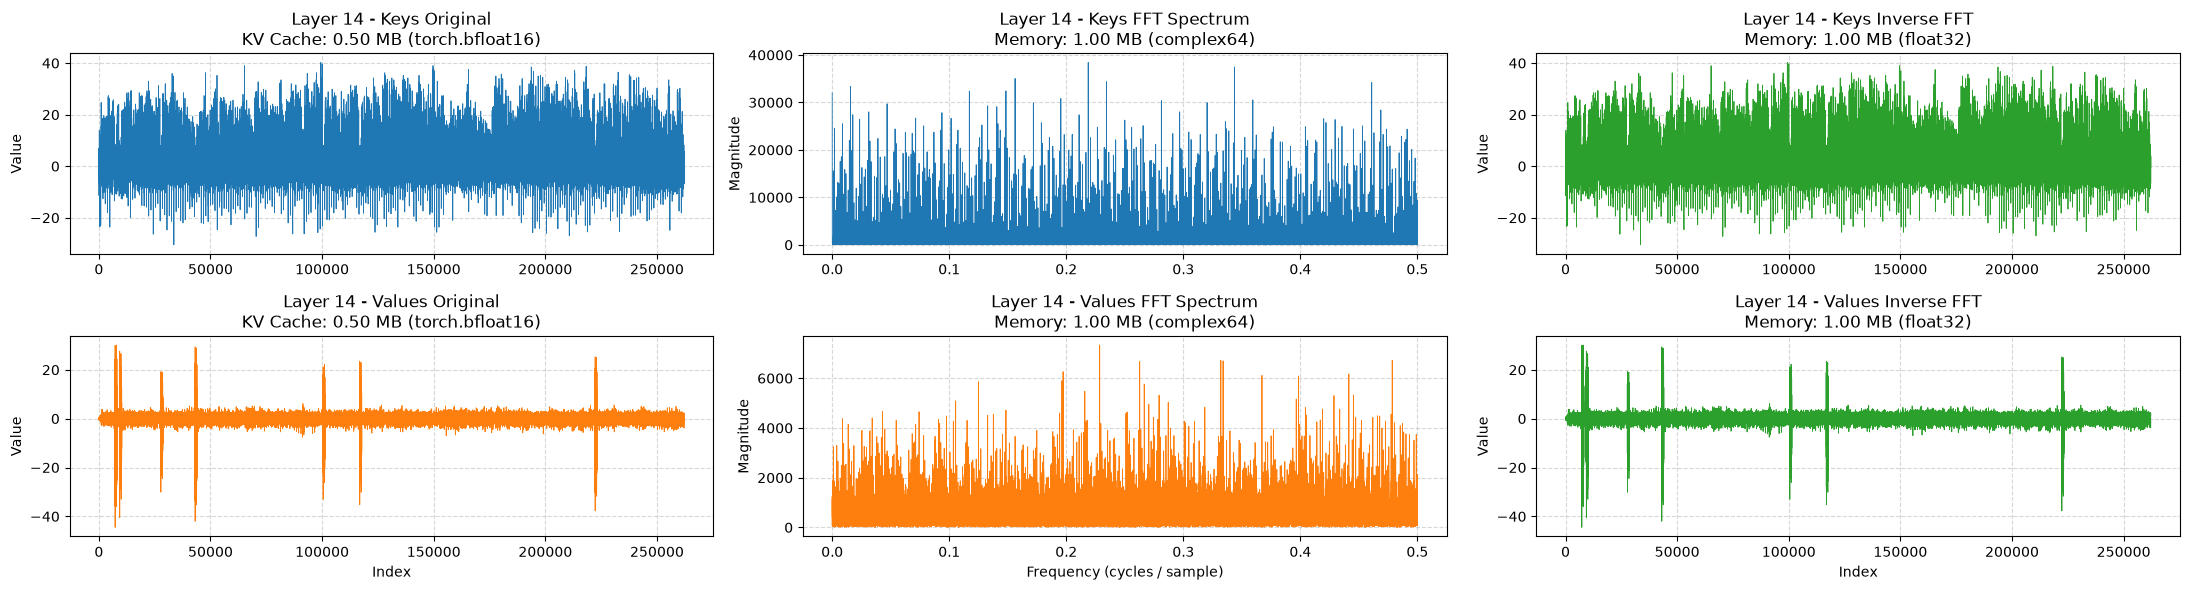

[Layer 27 Keys  ] len=262144  rfft bins=131073  DC=13261.86  IFFT max err=5.72e-06
    bin   47360  freq 0.180664  (period       5.5 samples)  |X|=41515.33
    bin    9984  freq 0.038086  (period      26.3 samples)  |X|=40866.16
    bin   51456  freq 0.196289  (period       5.1 samples)  |X|=37611.14
    bin   28928  freq 0.110352  (period       9.1 samples)  |X|=37150.81
    bin   40704  freq 0.155273  (period       6.4 samples)  |X|=36824.88
[Layer 27 Values] len=262144  rfft bins=131073  DC=9097.65  IFFT max err=7.63e-06
    bin   27904  freq 0.106445  (period       9.4 samples)  |X|=84633.12
    bin  123392  freq 0.470703  (period       2.1 samples)  |X|=83732.18
    bin  110848  freq 0.422852  (period       2.4 samples)  |X|=83282.32
    bin   87552  freq 0.333984  (period       3.0 samples)  |X|=82616.43
    bin   88320  freq 0.336914  (period       3.0 samples)  |X|=80894.88


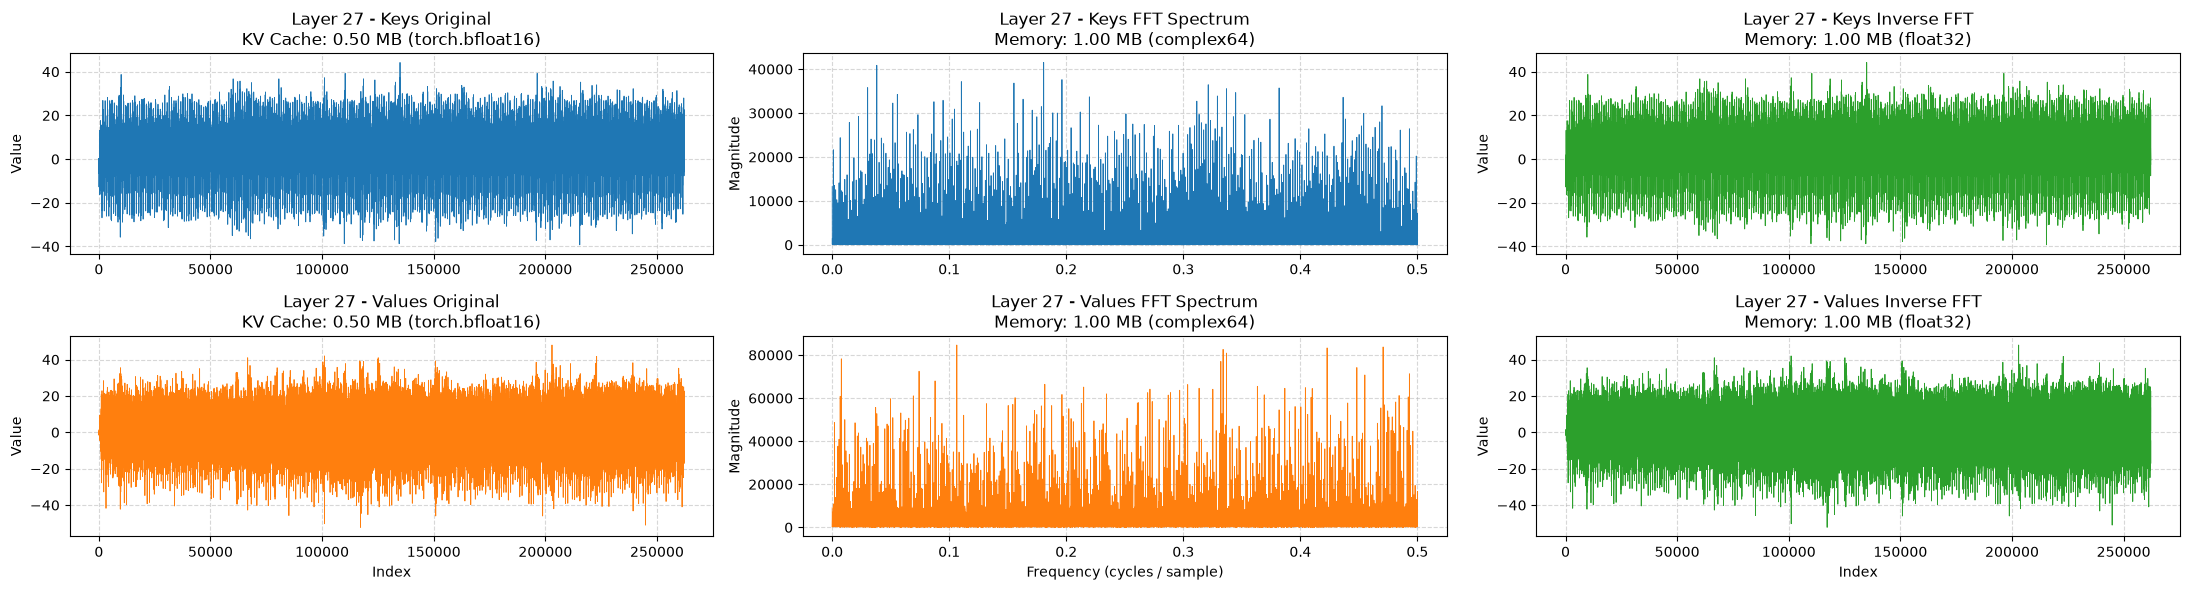

In [56]:
# 레이어별 K/V cache를 (batch, seq, heads, head_dim) 순서로 1차원으로 펼친 뒤 FFT
import numpy as np
from transformers import DynamicCache

probe_layers = [0, info["layers"] // 4, info["layers"] // 2, info["layers"] - 1]
PLOT_LAYERS = probe_layers          # 전부 보려면 range(info["layers"])
TOP_N = 5                           # 프린트할 피크 개수

cache = DynamicCache(config=model.config)
with torch.no_grad():
    tools.forward_logits(model, val_batches[0][:1], cache)
print("cache:", tuple(cache.layers[0].keys.shape), "(batch, heads, seq, head_dim)\n")

for i in PLOT_LAYERS:
    fig, axes = plt.subplots(2, 3, figsize=(22, 6))
    for row, (name, tensor, color) in enumerate((("Keys", cache.layers[i].keys, "tab:blue"),
                                                 ("Values", cache.layers[i].values, "tab:orange"))):
        cache_mem = tensor.numel() * tensor.element_size() / 1024**2

        # 1. 시퀀스 우선으로 펼치기
        x = tensor.permute(0, 2, 1, 3).detach().cpu().float().numpy().flatten()

        # 2. FFT / 3. IFFT
        spec = np.fft.rfft(x)
        mag = np.abs(spec)
        freqs = np.fft.rfftfreq(len(x))
        recon = np.fft.irfft(spec, n=len(x))

        axes[row, 0].plot(x, lw=0.6, color=color)
        axes[row, 0].set_title(f"Layer {i} - {name} Original\n"
                               f"KV Cache: {cache_mem:.2f} MB ({tensor.dtype})")
        axes[row, 1].plot(freqs, mag, lw=0.6, color=color)
        axes[row, 1].set_title(f"Layer {i} - {name} FFT Spectrum\n"
                               f"Memory: {spec.nbytes / 1024**2:.2f} MB ({spec.dtype})")
        axes[row, 2].plot(recon, lw=0.6, color="tab:green")
        axes[row, 2].set_title(f"Layer {i} - {name} Inverse FFT\n"
                               f"Memory: {recon.nbytes / 1024**2:.2f} MB ({recon.dtype})")
        axes[row, 0].set_ylabel("Value")
        axes[row, 1].set_ylabel("Magnitude")
        axes[row, 2].set_ylabel("Value")

        # 주파수 변환 결과 프린트
        top = np.argsort(mag[1:])[::-1][:TOP_N] + 1   # DC 제외 상위 피크
        print(f"[Layer {i:>2} {name:<6}] len={len(x)}  rfft bins={len(spec)}  "
              f"DC={mag[0]:.2f}  IFFT max err={np.abs(recon - x).max():.2e}")
        for b in top:
            period = 1 / freqs[b]
            print(f"    bin {b:>7}  freq {freqs[b]:.6f}  (period {period:9.1f} samples)  "
                  f"|X|={mag[b]:.2f}")

    for a in axes[1]:
        a.set_xlabel("Index")
    axes[1, 1].set_xlabel("Frequency (cycles / sample)")
    for a in axes.flat:
        a.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

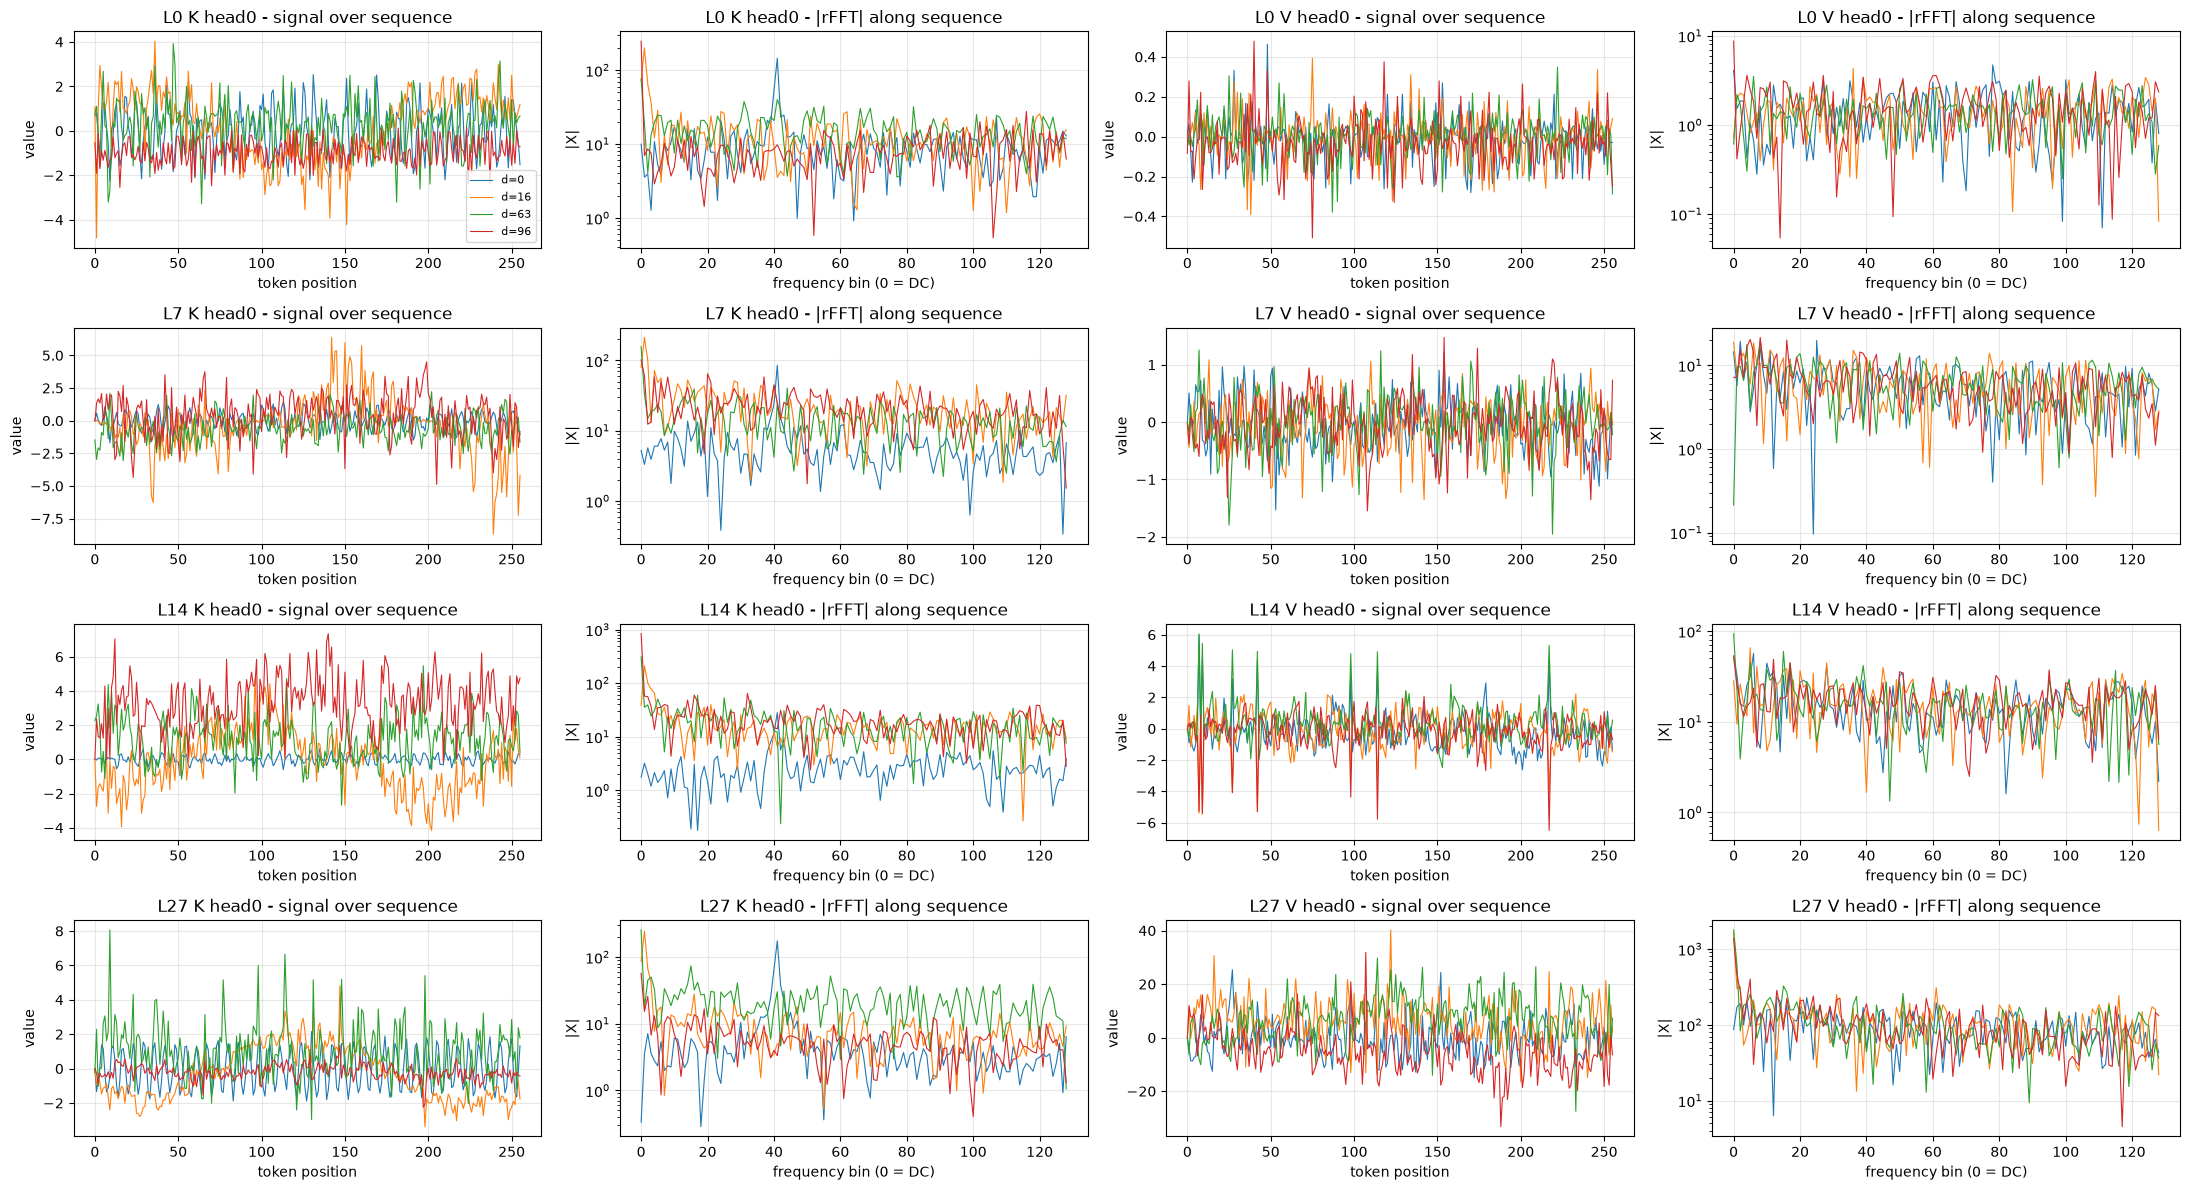

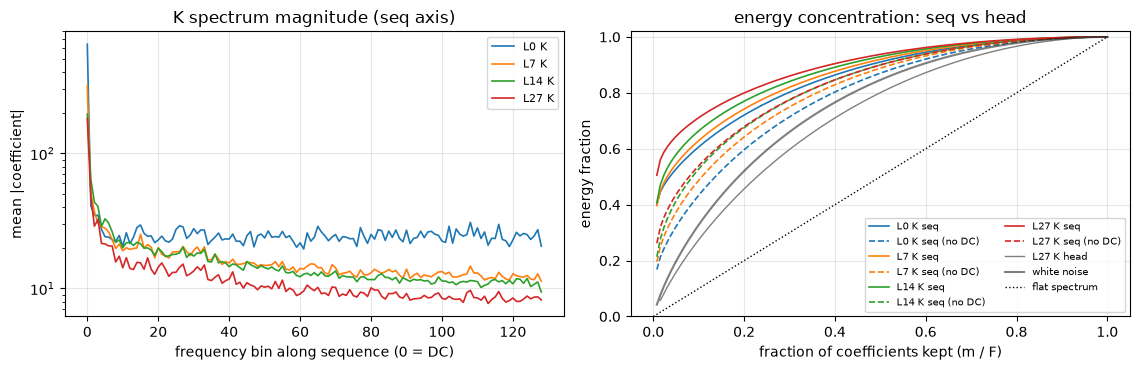

                F         K mean (min, max)         V mean (min, max)
        head   65      0.790 (0.638, 0.841)      0.839 (0.832, 0.841)
         seq  129      0.925 (0.903, 0.941)      0.877 (0.850, 0.905)
 seq (no DC)  128      0.893 (0.870, 0.909)      0.861 (0.846, 0.885)
 white noise  129                     0.843

기준은 0.5가 아니라 백색잡음 값(~0.84)이다. 이보다 얼마나 위에 있느냐가 실제 구조다.
seq와 seq (no DC)의 차이가 크면 DC(채널별 시간 평균)가 만든 착시다.


In [ ]:
# 같은 통계를 sequence 축으로. head·채널 (h, d)마다 길이 S 시계열을 FFT한다.
# DC(bin 0) = 채널별 시간 평균이라 K처럼 채널 bias가 크면 DC 하나가 에너지를 독차지한다.
# 그래서 DC 포함/제외를 둘 다 본다. x축은 F가 축마다 다르므로 m/F 비율로 맞춘다.
# --- 변환 전 시그널: 바로 위 셀의 cache에서 head 하나의 채널 몇 개를 시간축으로 본다.
# HF RoPE(rotate_half)는 채널 i와 i+D/2를 한 쌍으로 돌린다. i가 작을수록 빨리, 클수록 천천히 돈다.
SIG_HEAD = 0
SIG_CHANNELS = (0, 16, 63, 96)
fig, axes = plt.subplots(len(probe_layers), 4, figsize=(22, 3 * len(probe_layers)))
for r, layer in enumerate(probe_layers):
    for c, (name, tensor) in enumerate((("K", cache.layers[layer].keys),
                                        ("V", cache.layers[layer].values))):
        sig = tensor[0, SIG_HEAD].detach().cpu().float()          # (S, D)
        spec = torch.fft.rfft(sig, dim=0).abs()                   # (S//2+1, D)
        ax_sig, ax_fft = axes[r, 2 * c], axes[r, 2 * c + 1]
        for d in SIG_CHANNELS:
            ax_sig.plot(sig[:, d], lw=0.8, label=f"d={d}")
            ax_fft.plot(spec[:, d], lw=0.8, label=f"d={d}")
        ax_sig.set(title=f"L{layer} {name} head{SIG_HEAD} - signal over sequence",
                   xlabel="token position", ylabel="value")
        ax_fft.set(title=f"L{layer} {name} head{SIG_HEAD} - |rFFT| along sequence",
                   xlabel="frequency bin (0 = DC)", ylabel="|X|", yscale="log")
for a in axes.flat:
    a.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- 레이어 전체 통계
stats = tools.spectrum_stats(model, val_batches[0])               # head 축 (비교용)
stats_seq = tools.spectrum_stats(model, val_batches[0], axis="seq")
stats_seq_ac = tools.spectrum_stats(model, val_batches[0], axis="seq", drop_dc=True)
variants = {"head": stats, "seq": stats_seq, "seq (no DC)": stats_seq_ac}

fig, (ax_mag, ax_cum) = plt.subplots(1, 2, figsize=(11.5, 3.8))
for layer in probe_layers:
    line, = ax_mag.plot(stats_seq["mean_mag"][(layer, "k")], label=f"L{layer} K", lw=1.2)
    for name, style in (("seq", "-"), ("seq (no DC)", "--")):
        st = variants[name]
        x = torch.arange(1, st["n_freq"] + 1) / st["n_freq"]
        ax_cum.plot(x, st["energy_curve"][(layer, "k")], style, color=line.get_color(),
                    lw=1.2, label=f"L{layer} K {name}")
x = torch.arange(1, stats["n_freq"] + 1) / stats["n_freq"]
ax_cum.plot(x, stats["energy_curve"][(probe_layers[-1], "k")], color="gray", lw=1,
            label=f"L{probe_layers[-1]} K head")
# 기준선은 "계수 크기가 전부 같음"(점선)이 아니라 백색잡음이다. 샘플마다 크기순 정렬을
# 하므로 구조가 전혀 없는 잡음도 절반만 남기면 에너지의 ~0.84가 남는다.
noise = torch.fft.rfft(torch.randn(4096, val_batches[0].shape[-1]), dim=-1).abs().pow(2)
noise = noise.sort(dim=-1, descending=True).values
noise_curve = (noise.cumsum(-1) / noise.sum(-1, keepdim=True)).mean(0)
x = torch.arange(1, noise_curve.numel() + 1) / noise_curve.numel()
ax_cum.plot(x, noise_curve, "k", lw=1.5, alpha=0.5, label="white noise")
ax_cum.plot([0, 1], [0, 1], "k:", lw=1, label="flat spectrum")
ax_mag.set(xlabel="frequency bin along sequence (0 = DC)", ylabel="mean |coefficient|",
           title="K spectrum magnitude (seq axis)", yscale="log")
ax_cum.set(xlabel="fraction of coefficients kept (m / F)", ylabel="energy fraction",
           title="energy concentration: seq vs head", ylim=(0, 1.02))
for a in (ax_mag, ax_cum):
    a.grid(alpha=0.3)
ax_mag.legend(fontsize=8)
ax_cum.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

# 계수 절반을 남겼을 때 보존 에너지. 레이어 평균 (최소, 최대).
print(f"{'':>12} {'F':>4}  {'K mean (min, max)':>24}  {'V mean (min, max)':>24}")
for name, st in variants.items():
    half = st["n_freq"] // 2
    cells = []
    for which in ("k", "v"):
        kept = [float(st["energy_curve"][(l, which)][half - 1]) for l in range(info["layers"])]
        cells.append(f"{sum(kept)/len(kept):.3f} ({min(kept):.3f}, {max(kept):.3f})")
    print(f"{name:>12} {st['n_freq']:>4}  {cells[0]:>24}  {cells[1]:>24}")
half = noise_curve.numel() // 2

In [58]:
compressor = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
print("selector 파라미터:", sum(p.numel() for p in compressor.parameters()),
      f"(base model의 {sum(p.numel() for p in compressor.parameters())/sum(p.numel() for p in model.parameters()):.2%})")

baseline_rows = tools.sweep_ratios(
    model, compressor, val_batches,
    ratios=(1.0, 0.9375, 0.875, 0.75, 0.5, 0.25),
    modes=("energy", "lowpass", "random"),
)
summary["untrained_truncation"] = [
    {k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl", "ppl_teacher")}
    for r in baseline_rows
]

selector 파라미터: 2784824 (base model의 0.47%)
  energy keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  energy keep=0.9375  kl=   2.8235 agree=0.227 ppl=      504.00
  energy keep=0.875   kl=   4.0510 agree=0.135 ppl=     1728.34
  energy keep=0.75    kl=   5.6512 agree=0.070 ppl=     8511.84
  energy keep=0.5     kl=   9.3800 agree=0.022 ppl=   323562.17
  energy keep=0.25    kl=  10.6556 agree=0.006 ppl=  1007824.26
 lowpass keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
 lowpass keep=0.9375  kl=   1.8198 agree=0.347 ppl=      198.80
 lowpass keep=0.875   kl=   3.5322 agree=0.180 ppl=     1044.87
 lowpass keep=0.75    kl=   7.0741 agree=0.061 ppl=    33717.72
 lowpass keep=0.5     kl=   9.6242 agree=0.008 ppl=   354818.86
 lowpass keep=0.25    kl=  11.9881 agree=0.001 ppl=  3241240.59
  random keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  random keep=0.9375  kl=   5.9304 agree=0.073 ppl=    10266.47
  random keep=0.875   kl=   7.0395 agree=0.054 ppl=    29874.

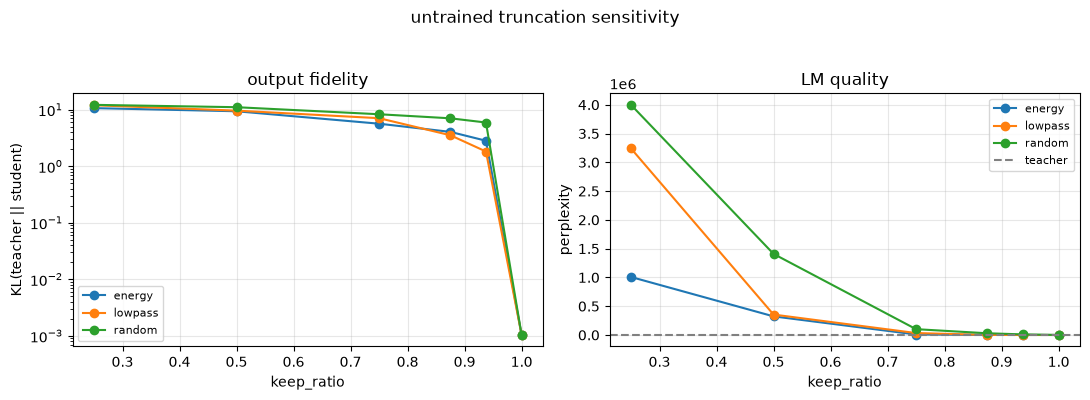

In [37]:
tools.plot_tradeoff(baseline_rows)
plt.suptitle("untrained truncation sensitivity", y=1.04)
plt.tight_layout()
plt.show()

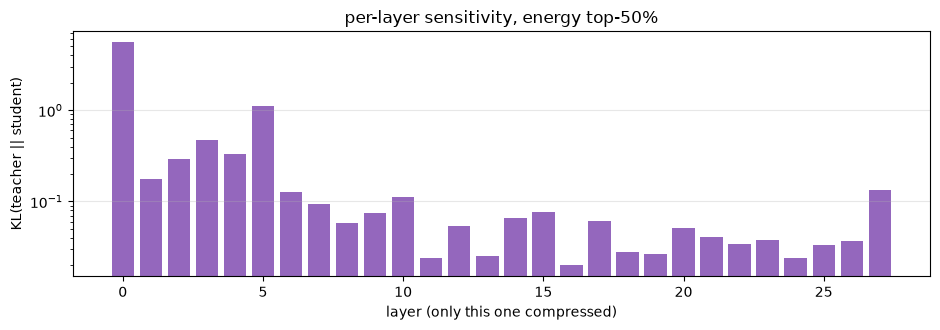

민감한 5개 레이어: [(0, 5.5229), (5, 1.1232), (3, 0.4671), (4, 0.3291), (2, 0.291)]
둔감한 5개 레이어: [(19, 0.0268), (13, 0.0252), (11, 0.0243), (24, 0.0238), (16, 0.02)]


In [59]:
sens = tools.layer_sensitivity(model, compressor, val_batches[:2], keep_ratio=0.5, mode="energy")
summary["layer_sensitivity"] = sens

fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.bar([r["layer"] for r in sens], [r["kl"] for r in sens], color="tab:purple")
ax.set(xlabel="layer (only this one compressed)", ylabel="KL(teacher || student)",
       title="per-layer sensitivity, energy top-50%", yscale="log")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

ranked = sorted(sens, key=lambda r: -r["kl"])
print("민감한 5개 레이어:", [(r["layer"], round(r["kl"], 4)) for r in ranked[:5]])
print("둔감한 5개 레이어:", [(r["layer"], round(r["kl"], 4)) for r in ranked[-5:]])

## 3. Selector와 캐시 sanity check

학습을 시작하기 전에 세 가지를 확인한다.

1. `mode="off"`면 압축 캐시가 원본과 **비트 단위로 같은** 출력을 내는가 (= 배선이 맞는가).
2. 초기화 상태의 mask가 1에 가까운가 (= student가 teacher에서 출발하는가).
3. mask를 전부 1로 둔 rFFT→irFFT 왕복이 얼마나 오차를 내는가 (= 측정의 바닥 노이즈).

In [39]:
# 1) off 모드는 완전 통과여야 한다
off = tools.evaluate(model, compressor, val_batches[:2], mode="off")
print(f"off      : KL={off['kl']:.3e}  agree={off['agree']:.4f}   <- 0 / 1.0 이어야 한다")

# 3) keep=100% 왕복 오차 = 측정 바닥선
full = tools.evaluate(model, compressor, val_batches[:2], mode="topk", keep_ratio=1.0)
print(f"keep 100%: KL={full['kl']:.3e}  agree={full['agree']:.4f}   <- fft 왕복 + bf16 반올림")

# 2) 초기 mask. FreqSelector는 마지막 Linear의 weight=0, bias=init_logit으로 시작한다.
init = tools.evaluate(model, compressor, val_batches[:2], mode="soft")
print(f"soft@init: KL={init['kl']:.3e}  agree={init['agree']:.4f}  usage={init['usage']:.4f}")
summary["sanity"] = {"off_kl": off["kl"], "roundtrip_kl": full["kl"],
                     "soft_init_kl": init["kl"], "soft_init_usage": init["usage"]}

off      : KL=0.000e+00  agree=1.0000   <- 0 / 1.0 이어야 한다
keep 100%: KL=1.032e-03  agree=0.9824   <- fft 왕복 + bf16 반올림
soft@init: KL=2.536e-03  agree=0.9648  usage=0.9820


## 4. Stage 1 — soft mask 학습

loss는 계획서 그대로다.

$$L = L_{KD} + \lambda_{sparse}\,\overline{mask} + \lambda_{budget}\,\mathrm{relu}(\overline{mask} - r_{target})^2$$

`train_selectors`는 처음 `warmup` 스텝 동안 sparsity/budget 계수를 0에서 선형으로 올린다.
초기 mask가 1에 가까워 budget 항의 기울기가 크고, 램프 없이 때리면 첫 스텝에서 selector가
통째로 망가진다 (KL이 0.003에서 1.2로 튄다).

In [40]:
TARGET_RATIO = 0.5

tools.set_seed(0)
compressor_soft = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
history = tools.train_selectors(
    model, compressor_soft, train_batches,
    epochs=EPOCHS, lr=LR,
    mode="soft",
    lambda_sparse=0.01,
    target_ratio=TARGET_RATIO,
    lambda_budget=5.0,
    warmup=20,
    log_every=max(1, len(train_batches) // 4),
)
torch.save(compressor_soft.state_dict(), RESULTS / "selectors" / "stage1_soft.pt")
print("peak GPU MiB:", torch.cuda.max_memory_allocated() / 2**20)

step    0  loss 0.06193  KL 0.00336  usage 0.982
step   22  loss 1.04293  KL 0.02176  usage 0.950
step   44  loss 0.80512  KL 0.16912  usage 0.854
step   66  loss 0.65040  KL 0.25456  usage 0.779
step   88  loss 0.40930  KL 0.19485  usage 0.704
step  110  loss 0.41075  KL 0.24769  usage 0.677
step  132  loss 0.32667  KL 0.18156  usage 0.666
step  154  loss 0.31343  KL 0.19225  usage 0.651
step  176  loss 0.29575  KL 0.18322  usage 0.646
step  198  loss 0.27624  KL 0.17701  usage 0.636
step  220  loss 0.27779  KL 0.18093  usage 0.635
step  242  loss 0.25230  KL 0.17414  usage 0.620
step  264  loss 0.26094  KL 0.18434  usage 0.619
peak GPU MiB: 5023.00048828125


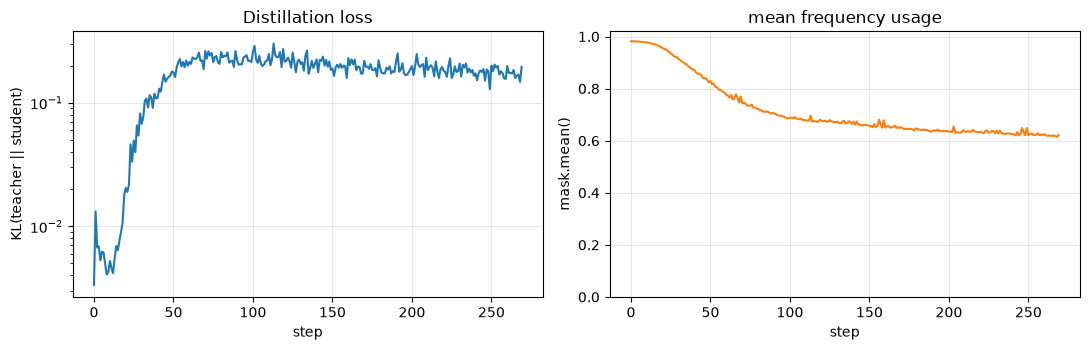

In [41]:
tools.plot_training(history)
plt.tight_layout()
plt.show()

soft mask: usage=0.618  KL=0.1994  agree=0.750  ppl=40.23 (teacher 36.46)


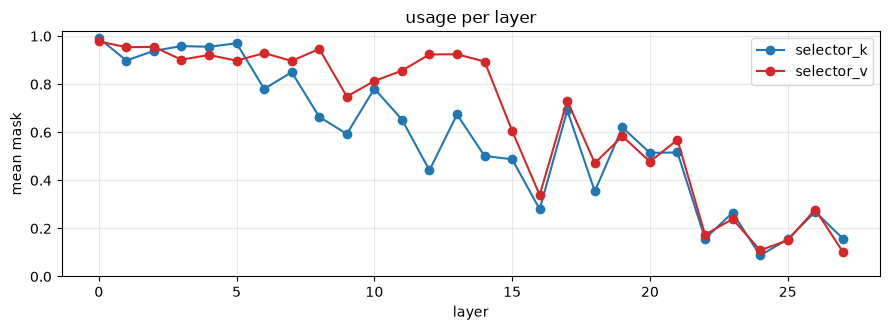

In [42]:
soft = tools.evaluate(model, compressor_soft, val_batches, mode="soft")
print(f"soft mask: usage={soft['usage']:.3f}  KL={soft['kl']:.4f}  "
      f"agree={soft['agree']:.3f}  ppl={soft['ppl']:.2f} (teacher {soft['ppl_teacher']:.2f})")
summary["stage1_soft"] = {k: soft[k] for k in ("kl", "agree", "ppl", "ppl_teacher", "usage")}

tools.plot_layer_usage(soft["usage_by_layer"])
plt.tight_layout()
plt.show()

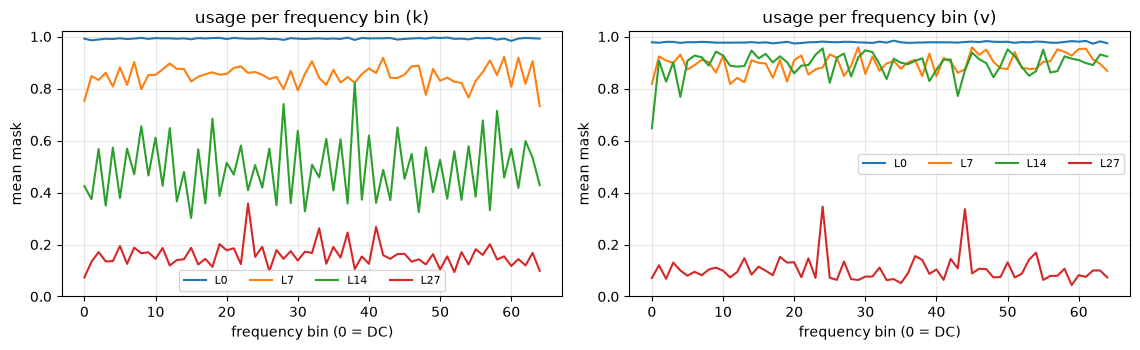

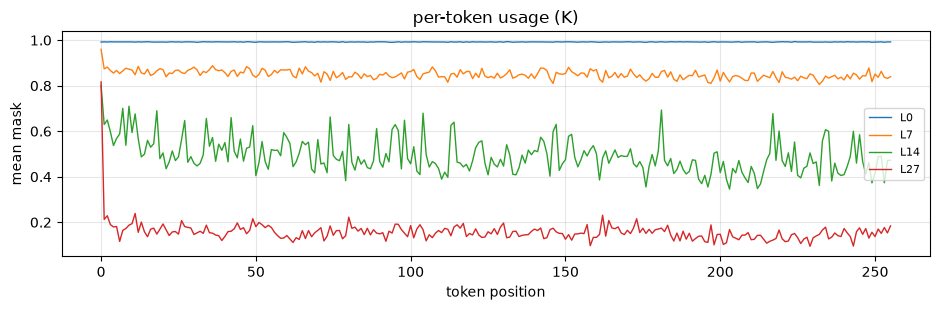

In [43]:
# selector가 어떤 주파수를 중요하게 보는가. 레이어마다 다른 패턴이 나오는지 본다.
compressor_soft.reset_log()
compressor_soft.mode, compressor_soft.collect = "soft", True
with torch.no_grad():
    cache = FFTCompressedCache(compressor_soft, config=model.config)
    tools.forward_logits(model, val_batches[0], cache)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
tools.plot_freq_profile(compressor_soft, probe_layers, "k", ax=axes[0])
tools.plot_freq_profile(compressor_soft, probe_layers, "v", ax=axes[1])
plt.tight_layout()
plt.show()

# 토큰 위치에 따라 사용률이 달라지는가 (= 진짜 "adaptive"인가)
fig, ax = plt.subplots(figsize=(9.5, 3.2))
for layer in probe_layers:
    ax.plot(compressor_soft.per_token_usage(layer, "k"), lw=1, label=f"L{layer}")
ax.set(xlabel="token position", ylabel="mean mask", title="per-token usage (K)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
del cache

### soft -> hard 간극

soft mask는 계수를 "약하게" 만들지 실제로 **버리지** 않는다. 캐시 바이트를 줄이려면 0/1 선택이
필요하다. 학습된 soft selector의 점수를 그대로 top-k로 잘라보면 그 간극이 보인다.

    topk keep=1.0     kl=   0.0010 agree=0.979 ppl=       36.45
    topk keep=0.875   kl=   5.4431 agree=0.101 ppl=     6658.25
    topk keep=0.75    kl=   7.8696 agree=0.052 ppl=    73281.56
    topk keep=0.5     kl=   9.2234 agree=0.019 ppl=   236986.30
    topk keep=0.25    kl=   8.6188 agree=0.014 ppl=   126946.00
  energy keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
  energy keep=0.875   kl=   4.0510 agree=0.135 ppl=     1728.34
  energy keep=0.75    kl=   5.6512 agree=0.070 ppl=     8511.84
  energy keep=0.5     kl=   9.3800 agree=0.022 ppl=   323562.17
  energy keep=0.25    kl=  10.6556 agree=0.006 ppl=  1007824.26
 lowpass keep=1.0     kl=   0.0010 agree=0.980 ppl=       36.44
 lowpass keep=0.875   kl=   3.5322 agree=0.180 ppl=     1044.87
 lowpass keep=0.75    kl=   7.0741 agree=0.061 ppl=    33717.72
 lowpass keep=0.5     kl=   9.6242 agree=0.008 ppl=   354818.86
 lowpass keep=0.25    kl=  11.9881 agree=0.001 ppl=  3241240.59


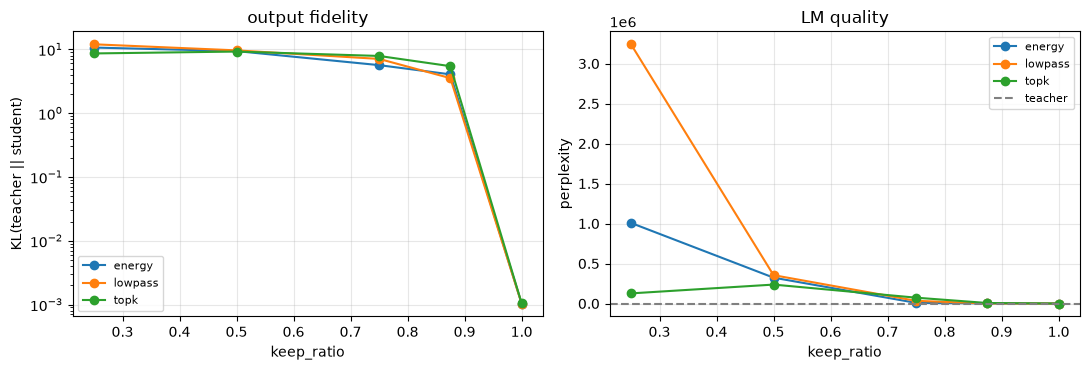

In [44]:
gap_rows = tools.sweep_ratios(
    model, compressor_soft, val_batches,
    ratios=(1.0, 0.875, 0.75, 0.5, 0.25),
    modes=("topk", "energy", "lowpass"),
)
summary["stage1_to_hard"] = [
    {k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl")} for r in gap_rows
]
tools.plot_tradeoff(gap_rows)
plt.tight_layout()
plt.show()

## 5. Stage 2 — hard selection 자체를 학습

soft로 학습한 selector를 사후에 잘라내는 대신, **처음부터 0/1 mask로 학습**한다.
`straight_through=True`가 forward에서는 hard mask를, backward에서는 sigmoid의 기울기를 쓰게 해
top-k 선택을 통과하는 gradient를 만들어 준다.

비율이 top-k로 고정되므로 sparsity/budget 항은 끈다 (`lambda_sparse=0, target_ratio=None`).
남는 것은 순수 distillation loss 하나다: *이 예산 안에서 무엇을 고를 것인가*.

In [45]:
RATIOS = (0.9375, 0.875, 0.75, 0.5) if not QUICK else (0.875, 0.5)

stage2 = {}
rows_learned = []
for ratio in RATIOS:
    tools.set_seed(0)
    comp = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
    print(f"\n=== keep_ratio {ratio} ===")
    tools.train_selectors(
        model, comp, train_batches,
        epochs=EPOCHS, lr=LR,
        mode="topk", keep_ratio=ratio, straight_through=True,
        lambda_sparse=0.0, target_ratio=None,
        log_every=max(1, len(train_batches) // 2),
    )
    row = tools.evaluate(model, comp, val_batches, mode="topk", keep_ratio=ratio,
                         collect_usage=False)
    row.pop("usage_by_layer", None)
    row["mode"] = "topk (learned, STE)"
    rows_learned.append(row)
    stage2[ratio] = comp
    torch.save(comp.state_dict(), RESULTS / "selectors" / f"stage2_topk_{ratio}.pt")
    print(f"-> KL={row['kl']:.4f} agree={row['agree']:.3f} ppl={row['ppl']:.2f}")


=== keep_ratio 0.9375 ===
step    0  loss 1.73666  KL 1.73666  usage 0.938
step   45  loss 1.52174  KL 1.52174  usage 0.938
step   90  loss 1.56289  KL 1.56289  usage 0.938
step  135  loss 1.63120  KL 1.63120  usage 0.938
step  180  loss 1.61762  KL 1.61762  usage 0.938
step  225  loss 1.79454  KL 1.79454  usage 0.938
-> KL=1.9638 agree=0.320 ppl=192.02

=== keep_ratio 0.875 ===
step    0  loss 3.54492  KL 3.54492  usage 0.877
step   45  loss 2.19082  KL 2.19082  usage 0.877
step   90  loss 2.12910  KL 2.12910  usage 0.877
step  135  loss 2.03091  KL 2.03091  usage 0.877
step  180  loss 2.41613  KL 2.41613  usage 0.877
step  225  loss 2.44905  KL 2.44905  usage 0.877
-> KL=2.3564 agree=0.269 ppl=270.60

=== keep_ratio 0.75 ===
step    0  loss 6.58765  KL 6.58765  usage 0.754
step   45  loss 3.57169  KL 3.57169  usage 0.754
step   90  loss 3.31636  KL 3.31636  usage 0.754
step  135  loss 3.14527  KL 3.14527  usage 0.754
step  180  loss 3.09537  KL 3.09537  usage 0.754
step  225  loss 2

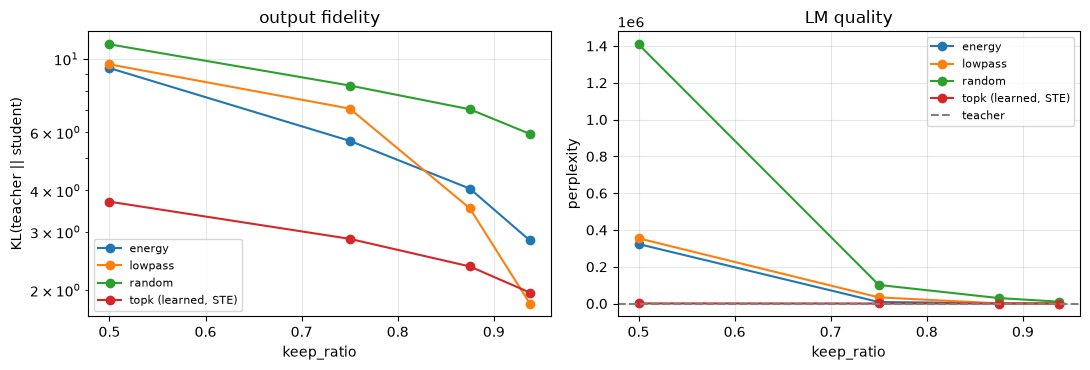

   keep  learned KL   energy KL  lowpass KL   random KL
 0.9375      1.9638      2.8235      1.8198      5.9304
  0.875      2.3564      4.0510      3.5322      7.0395
   0.75      2.8556      5.6512      7.0741      8.3057
    0.5      3.6992      9.3800      9.6242     11.0672


In [46]:
# 학습된 선택 vs 학습 없는 기준선들을 같은 축에 올린다.
rows_ref = [r for r in baseline_rows if r["keep_ratio"] in RATIOS]
trade_rows = rows_learned + rows_ref
summary["stage2"] = [{k: r[k] for k in ("mode", "keep_ratio", "kl", "agree", "ppl", "ppl_teacher")}
                     for r in trade_rows]

tools.plot_tradeoff(trade_rows)
plt.tight_layout()
plt.show()

print(f"{'keep':>7} {'learned KL':>11} {'energy KL':>11} {'lowpass KL':>11} {'random KL':>11}")
for ratio in RATIOS:
    def pick(mode):
        hit = [r for r in trade_rows if r["mode"] == mode and r["keep_ratio"] == ratio]
        return f"{hit[0]['kl']:.4f}" if hit else "-"
    print(f"{ratio:>7} {pick('topk (learned, STE)'):>11} {pick('energy'):>11} "
          f"{pick('lowpass'):>11} {pick('random'):>11}")

## 6. 어느 레이어에 예산을 쓸 것인가

2절의 레이어별 민감도를 실제 설정으로 옮긴다. 앞쪽 레이어 N개를 압축에서 제외하면 — 즉 예산을
둔감한 레이어에만 쓰면 — 같은 평균 압축률에서 품질이 어떻게 달라지는가.

In [47]:
SKIPS = (0, 2, 4, 8, 12) if not QUICK else (0, 4)
KEEP = 0.5

skip_rows = []
for skip in SKIPS:
    compressor.active_layers = set(range(skip, info["layers"]))
    r = tools.evaluate(model, compressor, val_batches, mode="energy", keep_ratio=KEEP,
                       collect_usage=False)
    # 압축한 레이어만 세어 실효 평균 사용률을 다시 계산한다
    compressed = info["layers"] - skip
    r["effective_keep"] = (compressed * KEEP + skip * 1.0) / info["layers"]
    r["skip"] = skip
    skip_rows.append(r)
    print(f"skip={skip:>2} ({compressed} layers @ keep {KEEP}) "
          f"-> 실효 사용률 {r['effective_keep']:.3f}  KL={r['kl']:.4f}  ppl={r['ppl']:.2f}")
compressor.active_layers = set(range(info["layers"]))
summary["layer_budget"] = [{k: r[k] for k in ("skip", "effective_keep", "kl", "agree", "ppl")}
                           for r in skip_rows]

skip= 0 (28 layers @ keep 0.5) -> 실효 사용률 0.500  KL=9.3800  ppl=323562.17
skip= 2 (26 layers @ keep 0.5) -> 실효 사용률 0.536  KL=5.6522  ppl=9368.67
skip= 4 (24 layers @ keep 0.5) -> 실효 사용률 0.571  KL=4.7382  ppl=3900.34
skip= 8 (20 layers @ keep 0.5) -> 실효 사용률 0.643  KL=1.8579  ppl=228.22
skip=12 (16 layers @ keep 0.5) -> 실효 사용률 0.714  KL=1.0848  ppl=107.55


In [48]:
# 가장 좋았던 skip 값으로 다시 학습해, 레이어 선택과 학습을 합친 효과를 본다.
best_skip = min(skip_rows, key=lambda r: r["kl"])["skip"]
print("best skip:", best_skip)

tools.set_seed(0)
comp_skip = KVFreqCompressor(info["layers"], info["head_dim"]).to(model.device)
comp_skip.active_layers = set(range(best_skip, info["layers"]))
tools.train_selectors(
    model, comp_skip, train_batches,
    epochs=EPOCHS, lr=LR,
    mode="topk", keep_ratio=KEEP, straight_through=True,
    lambda_sparse=0.0, target_ratio=None,
    log_every=max(1, len(train_batches) // 2),
)
best = tools.evaluate(model, comp_skip, val_batches, mode="topk", keep_ratio=KEEP,
                      collect_usage=False)
print(f"skip={best_skip} + 학습: KL={best['kl']:.4f} agree={best['agree']:.3f} "
      f"ppl={best['ppl']:.2f} (teacher {best['ppl_teacher']:.2f})")
torch.save(comp_skip.state_dict(), RESULTS / "selectors" / f"stage3_skip{best_skip}_keep{KEEP}.pt")
summary["layer_budget_trained"] = {"skip": best_skip, "keep": KEEP,
                                   **{k: best[k] for k in ("kl", "agree", "ppl", "ppl_teacher")}}

best skip: 12
step    0  loss 1.53063  KL 1.53063  usage 0.492
step   45  loss 0.52209  KL 0.52209  usage 0.492
step   90  loss 0.42080  KL 0.42080  usage 0.492
step  135  loss 0.42407  KL 0.42407  usage 0.492
step  180  loss 0.38856  KL 0.38856  usage 0.492
step  225  loss 0.37290  KL 0.37290  usage 0.492
skip=12 + 학습: KL=0.4313 agree=0.639 ppl=49.07 (teacher 36.46)


## 7. Stage 3 — 실제 KV cache 압축

여기까지의 `FFTCompressedCache`는 **재구성된 D차원 실수 벡터**를 저장한다. 즉 정보량은 줄었지만
바이트는 그대로다. 실제로 줄이려면 주파수 index와 complex 계수만 들고 있어야 한다.

`SparseSpectralCache`가 그걸 한다. 토큰·head마다 상위 `keep`개를 골라

```
idx  : int16        (B, H, S, keep)
re   : bfloat16     (B, H, S, keep)
im   : bfloat16     (B, H, S, keep)
```

로 저장하고, attention에 줄 때만 0으로 채운 spectrum에 scatter해 irFFT한다.

**오버헤드를 정직하게 세야 한다.** 계수 하나는 실수부+허수부로 4바이트인데, 원본은 bf16 2바이트
한 칸이다. 즉 계수 **하나를 남기면 원본 두 칸 값을 쓴다**. rFFT 계수가 `D/2+1`개이므로
"계수 절반"은 바이트로 "원본 전체와 거의 같다". 거기에 어느 주파수를 골랐는지도 저장해야 한다.

In [49]:
seq = SEQ_LEN
print(f"seq_len={seq}, {info['layers']} layers, {info['kv_heads']} kv heads, head_dim={info['head_dim']}\n")
dense = tools.dense_kv_bytes(info, seq)
print(f"{'keep':>5} {'ratio':>7} {'bitmask':>12} {'vs dense':>9} {'index':>12} {'vs dense':>9}")
mem_rows = []
for keep in (65, 48, 32, 24, 16, 8, 4):
    keep = min(keep, info["n_freq"])
    bm = tools.spectral_kv_bytes(info, seq, keep, index_scheme="bitmask")
    ix = tools.spectral_kv_bytes(info, seq, keep, index_scheme="index")
    mem_rows.append({"keep": keep, "ratio": keep / info["n_freq"],
                     "bitmask": bm, "index": ix, "dense": dense})
    print(f"{keep:>5} {keep/info['n_freq']:>7.3f} {bm/2**20:>10.2f}MB {bm/dense:>8.2f}x "
          f"{ix/2**20:>10.2f}MB {ix/dense:>8.2f}x")
print(f"\ndense: {dense/2**20:.2f}MB")
summary["memory_table"] = mem_rows

seq_len=256, 28 layers, 8 kv heads, head_dim=128

 keep   ratio      bitmask  vs dense        index  vs dense
   65   1.000      29.42MB     1.05x      42.66MB     1.52x
   48   0.738      21.98MB     0.79x      31.50MB     1.12x
   32   0.492      14.98MB     0.54x      21.00MB     0.75x
   24   0.369      11.48MB     0.41x      15.75MB     0.56x
   16   0.246       7.98MB     0.29x      10.50MB     0.38x
    8   0.123       4.48MB     0.16x       5.25MB     0.19x
    4   0.062       2.73MB     0.10x       2.62MB     0.09x

dense: 28.00MB


In [50]:
# 실제 캐시로 디코딩해 본다. 바이트는 캐시가 들고 있는 텐서에서 직접 센다.
PROMPT = "Explain in two sentences why the sky is blue."
KEEP_N = 32

ref = tools.greedy_generate(model, tok, PROMPT, max_new_tokens=48)
print(f"[원본]  {ref['tok_per_s']:.1f} tok/s\n{ref['text']!r}\n")

for comp_name, comp_obj in (("untrained", compressor), (f"trained skip{best_skip}", comp_skip)):
    out = tools.greedy_generate(
        model, tok, PROMPT, max_new_tokens=48,
        make_cache=lambda c=comp_obj: SparseSpectralCache(c, keep=KEEP_N, config=model.config),
    )
    print(f"[sparse {KEEP_N}/{info['n_freq']}, {comp_name}]  {out['tok_per_s']:.1f} tok/s  "
          f"cache {out['footprint_bytes']/2**20:.2f}MB\n{out['text']!r}\n")
    summary[f"stage3_gen_{comp_name}"] = {k: out[k] for k in
                                          ("text", "tok_per_s", "footprint_bytes")}
summary["stage3_gen_ref"] = {k: ref[k] for k in ("text", "tok_per_s")}

[원본]  129.0 tok/s
"The sky appears blue because of the way light interacts with the Earth's atmosphere, where shorter wavelengths of light (blue) are scattered more efficiently than longer wavelengths (red and orange). This scattering causes the blue light to be scattered in all directions"

[sparse 32/65, untrained]  65.0 tok/s  cache 5.74MB
'лотymrythofzeotom.typstitute-tableathingatory่ายotenof-#elif-extr.-mapb-- f. odinousetically openL,abcdefghijklmnopumer-wheel seneut- Hartfordace board mutual痿Taylor tym-ай'

[sparse 32/65, trained skip12]  64.3 tok/s  cache 5.74MB
'.. the.. the example is... the. example to... the costcplusplus.,..... over o乎 of. way_w-plus.. time ofay_tetae? with..'



`tok/s`가 원본보다 느린 것은 예상된 결과다. 매 스텝 rFFT/irFFT와 scatter를 추가로 돌리고,
게다가 `SparseSpectralCache`는 과거 전체를 매번 복원한다 (즉 O(S) 작업을 O(S^2)로 만든다).
이 절의 목적은 속도가 아니라 **압축된 표현만 들고도 디코딩이 돌아가는지**와 **실제 바이트**다.
속도를 재려면 복원을 증분으로 바꾸거나 spectral domain에서 직접 attention을 계산해야 한다.

## 8. 종합

성능 저하 대비 KV cache 감소량이 최종 지표다. `keep` 하나를 고르면 바이트는 계산으로 나오고,
품질은 위에서 측정한 값을 그대로 쓴다.

In [51]:
print(f"teacher perplexity: {soft['ppl_teacher']:.2f}\n")
header = f"{'setting':>34} {'keep':>7} {'KL':>9} {'agree':>7} {'ppl':>12} {'KV bytes':>10}"
print(header)
print("-" * len(header))

def line(name, keep_ratio, row, bytes_ratio=None):
    keep_n = max(1, round(keep_ratio * info["n_freq"]))
    nbytes = tools.spectral_kv_bytes(info, SEQ_LEN, keep_n, index_scheme="bitmask")
    ratio = bytes_ratio if bytes_ratio is not None else nbytes / dense
    print(f"{name:>34} {keep_ratio:>7.3f} {row['kl']:>9.4f} {row['agree']:>7.3f} "
          f"{row['ppl']:>12.2f} {ratio:>9.2f}x")

line("teacher (no compression)", 1.0, {"kl": 0.0, "agree": 1.0, "ppl": soft["ppl_teacher"]}, 1.0)
line("stage1 soft (no byte saving)", 1.0, soft, 1.0)
for row in rows_learned:
    line("stage2 learned top-k", row["keep_ratio"], row)
for row in rows_ref:
    line(f"  baseline {row['mode']}", row["keep_ratio"], row)
line(f"stage2 + skip first {best_skip}", KEEP, best)

(RESULTS / "fft_kv_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(f"\n-> {RESULTS/'fft_kv_summary.json'} 저장")

teacher perplexity: 36.46

                           setting    keep        KL   agree          ppl   KV bytes
------------------------------------------------------------------------------------
          teacher (no compression)   1.000    0.0000   1.000        36.46      1.00x
      stage1 soft (no byte saving)   1.000    0.1994   0.750        40.23      1.00x
              stage2 learned top-k   0.938    1.9638   0.320       192.02      0.99x
              stage2 learned top-k   0.875    2.3564   0.269       270.60      0.93x
              stage2 learned top-k   0.750    2.8556   0.215       419.40      0.80x
              stage2 learned top-k   0.500    3.6992   0.117       930.27      0.54x
                   baseline energy   0.938    2.8235   0.227       504.00      0.99x
                   baseline energy   0.875    4.0510   0.135      1728.34      0.93x
                   baseline energy   0.750    5.6512   0.070      8511.84      0.80x
                   baseline energy   0

### 읽는 법과 다음 수

표의 `KV bytes` 열이 이 실험의 손익계산서다. 계수 하나당 실수부+허수부 4바이트를 쓰므로,
**계수를 절반으로 줄여도 바이트는 거의 그대로**다. 실질적 이득은 `keep`이 `n_freq/2`보다 한참
아래로 내려가야 나오고, 품질은 그 전에 먼저 무너진다. 그래서 이 축으로 이득을 보려면

- **계수를 더 작은 dtype으로** — fp8이나 int8 양자화. 2바이트 대신 1바이트면 손익분기점이 두 배로 밀린다.
- **head_dim이 아니라 sequence 축으로 FFT** — 인접 토큰의 K/V는 상관이 높다. 계획서는 head_dim 축을
  명시했지만, KV cache의 실제 중복은 시간 축에 있다. `spectral_filter`를 `transpose` 한 번으로 돌려쓸 수 있다.
- **RoPE 적용 전 K** — RoPE는 차원 i와 i+D/2를 섞어 스펙트럼에 주기 2의 톱니를 만든다 (2절 왼쪽 그림).
  pre-RoPE K를 저장하고 읽을 때 회전시키면 더 매끄러운 스펙트럼을 다룰 수 있다.
- **레이어별 예산 배분** — 6절이 보여주듯 레이어 민감도 차이가 수백 배다. 균일 예산은 낭비다.
- **큰 모델** — head_dim이 같아도 레이어 수와 head 수가 많아지면 중복이 늘어날 수 있다.

가설 자체에 대한 판정은 위 숫자로 한다. `energy`/`lowpass`/`random` 대비 학습된 selector가
얼마나 앞서는지가 "**적응형 선택이 학습 가능한가**"에 대한 답이고, teacher 대비 절대 품질이
"**FFT basis에 쓸 만한 sparsity가 있는가**"에 대한 답이다. 두 질문은 따로 답이 나올 수 있다.